In [20]:
import duckdb



# Change this to some alias loaded by env file
con = duckdb.connect("/home/cwk/ebird-education/Data-files/duckdb/ebd_AL_full.duckdb")

num_rows = con.sql("SELECT count(*) from ebd").fetchall()[0][0]

num_media = con.sql(
'''
SELECT count(*) from ebd
WHERE "HAS MEDIA" = true;
''').fetchall()[0][0]

print(f"Total Rows: {num_rows:,}")
print(f"Rows with Media: {num_media:,}")
print(f"Rows without Media: {num_rows - num_media:,}")
print(f"Percentage of Rows with Media: {num_media / num_rows * 100:.2f}%")


Total Rows: 9,444,141
Rows with Media: 270,044
Rows without Media: 9,174,097
Percentage of Rows with Media: 2.86%


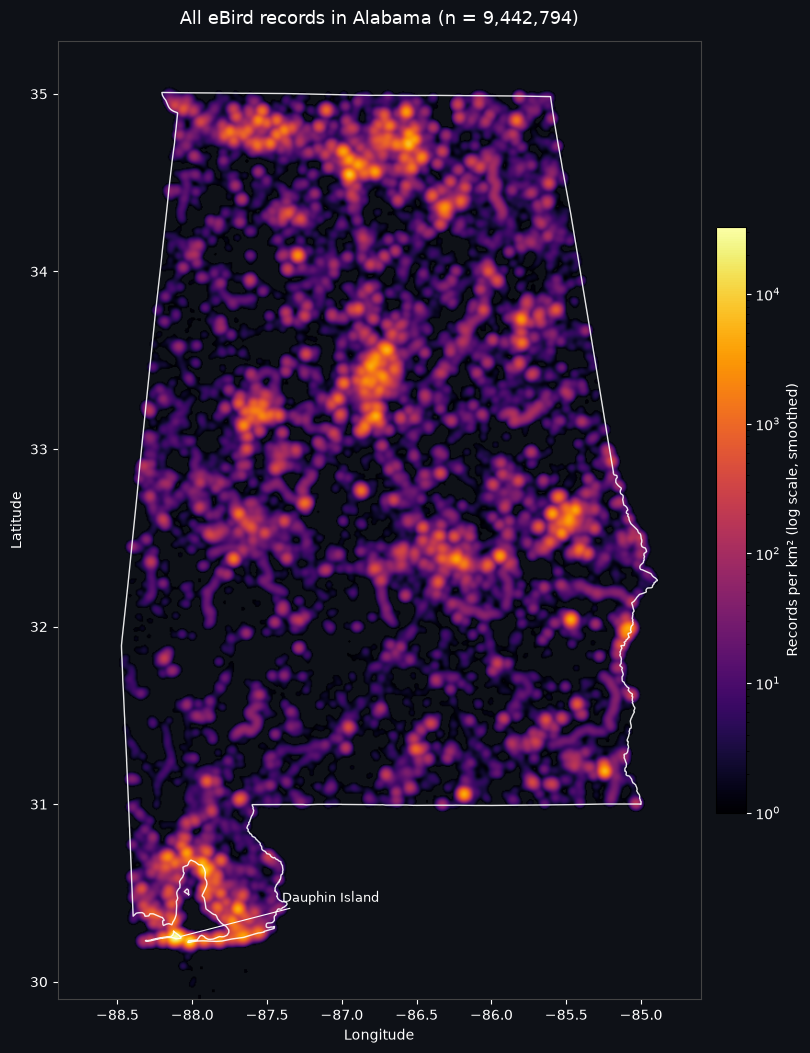

In [21]:
# Reusable density-map function, used for both the all-records and media-only maps below
import json
import numpy as np
import datashader as ds
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter

# View windows as (lon_min, lon_max, lat_min, lat_max) in degrees. Fixed so stray
# points far outside the area don't stretch the view; a few points near the border
# may fall outside the outline, which is fine.
ALABAMA = (-88.9, -84.6, 29.9, 35.3)
DAUPHIN = (-88.40, -88.02, 30.17, 30.32)   # Dauphin Island with a little margin

# State outline (US Census 2010 cartographic boundary, 1:500k)
with open("alabama_boundary.geojson") as f:
    _geom = json.load(f)["features"][0]["geometry"]
_polygons = _geom["coordinates"] if _geom["type"] == "MultiPolygon" else [_geom["coordinates"]]


def plot_density_map(df, title, vmin=0.02, view=ALABAMA, sigma=3, annotate=True):
    """Heat map of records per km^2 from a dataframe with LONGITUDE/LATITUDE columns.

    view: (lon_min, lon_max, lat_min, lat_max); sigma: smoothing in pixels.
    """
    LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = view
    # Datashader does the heavy lifting: count records per pixel on a regular grid.
    # A plain lon/lat grid keeps the axes readable in degrees; the aspect ratio
    # is corrected using cos(latitude).
    lat_mid = (LAT_MIN + LAT_MAX) / 2
    aspect = (LAT_MAX - LAT_MIN) / ((LON_MAX - LON_MIN) * np.cos(np.radians(lat_mid)))
    W = 700
    H = int(W * aspect)
    canvas = ds.Canvas(plot_width=W, plot_height=H,
                       x_range=(LON_MIN, LON_MAX), y_range=(LAT_MIN, LAT_MAX))
    agg = canvas.points(df, "LONGITUDE", "LATITUDE", agg=ds.count())
    counts = agg.values.astype(float)
    n_in_view = int(counts.sum())   # records inside the view window

    # Convert to records per km^2 so the legend has a physical meaning.
    km_per_deg = 111.32
    px_w_km = (LON_MAX - LON_MIN) / W * km_per_deg * np.cos(np.radians(lat_mid))
    px_h_km = (LAT_MAX - LAT_MIN) / H * km_per_deg
    density = gaussian_filter(counts, sigma=sigma) / (px_w_km * px_h_km)   # light smoothing -> heatmap look
    density[density < vmin] = np.nan    # leave (nearly) empty areas blank

    map_aspect = (LAT_MAX - LAT_MIN) / ((LON_MAX - LON_MIN) * np.cos(np.radians(lat_mid)))
    fig, ax = plt.subplots(figsize=(10, max(4.5, 10 * map_aspect * 0.85)), facecolor="#0e1117")
    ax.set_facecolor("#0e1117")
    im = ax.imshow(density, origin="lower", cmap="inferno",
                   norm=LogNorm(vmin=vmin, vmax=np.nanmax(density)),
                   extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX),
                   aspect=1 / np.cos(np.radians(lat_mid)), interpolation="bilinear")

    cbar = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02)
    cbar.set_label("Records per km² (log scale, smoothed)", color="white")
    cbar.ax.yaxis.set_tick_params(color="white")
    plt.setp(cbar.ax.get_yticklabels(), color="white")

    ax.set_title(f"{title} (n = {n_in_view:,})", color="white", fontsize=13, pad=12)
    ax.set_xlabel("Longitude", color="white")
    ax.set_ylabel("Latitude", color="white")
    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_color("#444")

    # State outline, drawn on top of the heat map (outer ring of each polygon only)
    for poly in _polygons:
        ring = np.array(poly[0])
        ax.plot(ring[:, 0], ring[:, 1], color="white", lw=1.0, alpha=0.9)

    ax.set_xlim(LON_MIN, LON_MAX)   # the state outline would otherwise autoscale the view back out
    ax.set_ylim(LAT_MIN, LAT_MAX)
    if annotate:
        ax.annotate("Dauphin Island", xy=(-88.1, 30.25), xytext=(-87.4, 30.45), color="white", fontsize=9,
                    arrowprops=dict(arrowstyle="-", color="white", lw=0.8))
    plt.show()


# Plot all records. Only the two coordinate columns are loaded (~9.4M rows).
df_all = con.sql(
'''
SELECT LATITUDE, LONGITUDE FROM ebd
WHERE LATITUDE IS NOT NULL AND LONGITUDE IS NOT NULL;
''').fetchdf()

plot_density_map(df_all, "All eBird records in Alabama", vmin=1)

In [22]:
# Get data with media
df_has_media = con.sql(
'''
SELECT * from ebd
WHERE "HAS MEDIA" = true;
''').fetchdf()

# This took awhile to run (3.6s)
coordinates = df_has_media[["LATITUDE", "LONGITUDE"]].values.tolist()

print(f"Coordinates of Rows with Media: {coordinates[:5]}")  # Print first 5 coordinates

Coordinates of Rows with Media: [[34.4592129, -86.3333241], [34.4592129, -86.3333241], [34.4592129, -86.3333241], [34.4592129, -86.3333241], [34.4592129, -86.3333241]]


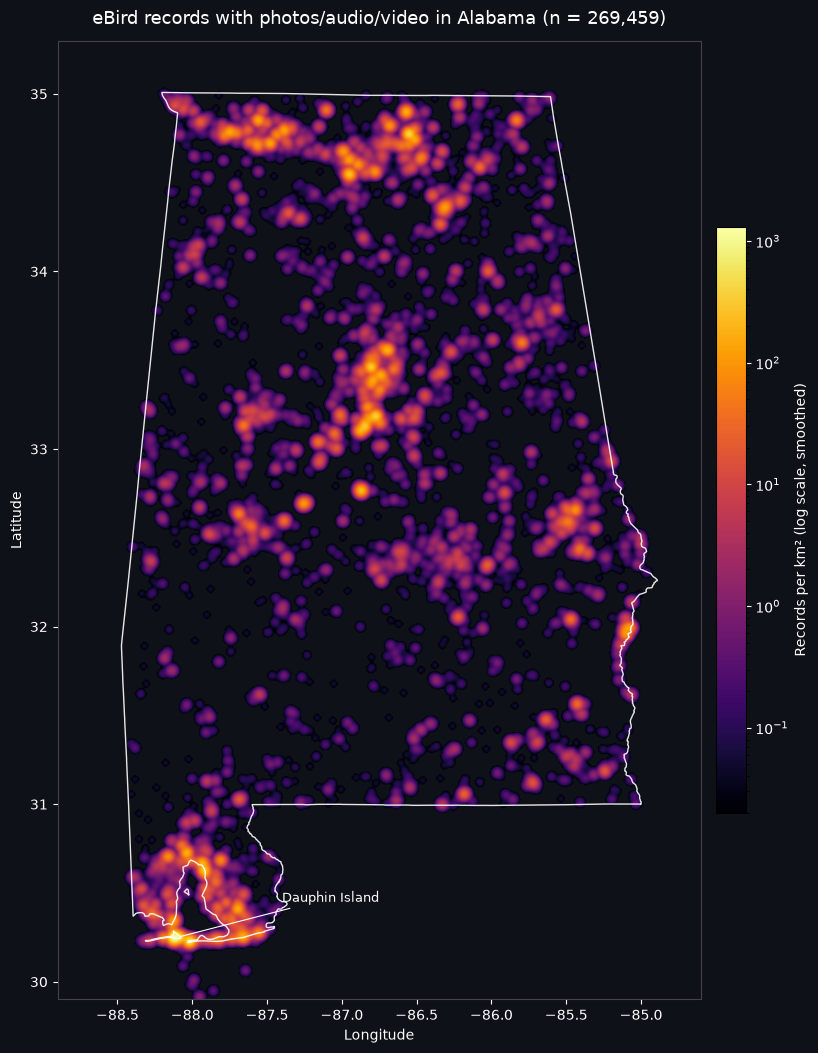

In [23]:
# Plot media on a map
plot_density_map(df_has_media, "eBird records with photos/audio/video in Alabama", vmin=0.02)

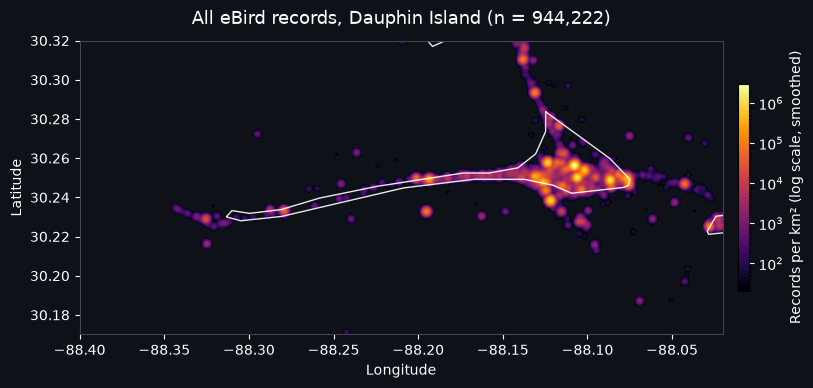

In [24]:
# Zoom: all records, Dauphin Island only (reuses df_all loaded above)
# Smaller sigma and a higher floor, since this area is far denser per km² than the state average
plot_density_map(df_all, "All eBird records, Dauphin Island", vmin=20, view=DAUPHIN, sigma=2, annotate=False)

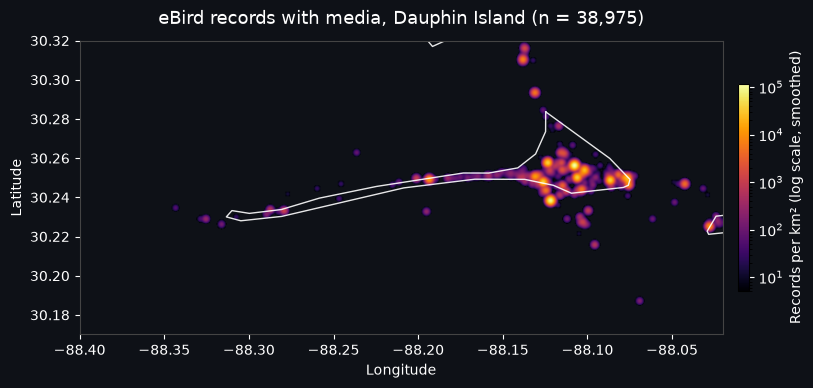

In [25]:
# Zoom: media records, Dauphin Island only
plot_density_map(df_has_media, "eBird records with media, Dauphin Island", vmin=5, view=DAUPHIN, sigma=2, annotate=False)

In [26]:
# percentage of records with media on Dauphin Island
num_rows_dauphin = con.sql(
'''
SELECT count(*) from ebd
WHERE LATITUDE BETWEEN 30.17 AND 30.32 AND LONGITUDE BETWEEN -88.40 AND -88.02;
''').fetchall()[0][0]   

num_media_dauphin = con.sql(
'''
SELECT count(*) from ebd
WHERE LATITUDE BETWEEN 30.17 AND 30.32 AND LONGITUDE BETWEEN -88.40 AND -88.02 AND "HAS MEDIA" = true;
''').fetchall()[0][0]

print(f"Total Rows on Dauphin Island: {num_rows_dauphin:,}")
print(f"Rows with Media on Dauphin Island: {num_media_dauphin:,}")
print(f"Rows without Media on Dauphin Island: {num_rows_dauphin - num_media_dauphin:,}")
print(f"Percentage of Rows with Media on Dauphin Island: {num_media_dauphin / num_rows_dauphin * 100:.2f}%")

Total Rows on Dauphin Island: 944,222
Rows with Media on Dauphin Island: 38,975
Rows without Media on Dauphin Island: 905,247
Percentage of Rows with Media on Dauphin Island: 4.13%
